# Kavach AI: EDA and modelling

Data Science Lab mini project, Sem VII 2026-27, Dept. of IT, SIES GST (Group 17).

This notebook **does not retrain**. It loads the data through `src/preprocess.py` and reads every
model result from `artifacts/metrics.json` (written by `src/train.py` + `src/evaluate.py` +
`src/explain.py`), so the numbers here match the app exactly. All figures are saved to
`reports/figures/` (PNG, 150 dpi, white background).

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.feature_extraction.text import CountVectorizer

from src.preprocess import (CLASSES, TOKEN_PATTERN, add_features, clean_text, hinglish_only,
                            load_hinglish, load_sentinel, load_uci, template_key)
from src.evaluate import (CLASS_COLORS, FIGURES, GRID, INK, INK_2, _save, _style,
                          plot_confusion, plot_model_comparison, plot_ood)
from src.predict import analyse, load_model, predict
from src.explain import explain_global, explain_local, plot_top_words

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})
pd.set_option("display.max_colwidth", 130)

M = json.loads((ROOT / "artifacts" / "metrics.json").read_text())
CM = json.loads((ROOT / "artifacts" / "confusion_matrices.json").read_text())
DEMO = {m["id"]: m for m in json.loads((ROOT / "demo_samples" / "messages.json").read_text())}

def show(name):
    display(Image(filename=str(FIGURES / name), width=900))

## 1. Data overview and honesty checks

| Dataset | Role |
|---|---|
| Sentinel multiclass (Shade63/scam-classification-multiclass) | Primary train/test, 5 classes |
| Hinglish & English scam text (bolewara, CC BY 4.0) | Out-of-domain (binary) |
| UCI SMS Spam Collection (CC BY 4.0) | Out-of-domain (binary) |

In [2]:
sent, sstats = load_sentinel()
uci, uci_drop = load_uci()
hing, hing_drop = load_hinglish()
hing_only = hinglish_only(hing, uci)

overview = pd.DataFrame([
    {"dataset": "Sentinel multiclass", "raw rows": sstats["raw_rows"],
     "exact duplicates dropped": sstats["duplicates_removed"], "rows used": len(sent),
     "labels": ", ".join(f"{c}: {n}" for c, n in sent["label_name"].value_counts().items())},
    {"dataset": "UCI SMS Spam", "raw rows": len(uci) + uci_drop, "exact duplicates dropped": uci_drop,
     "rows used": len(uci), "labels": f"ham: {(uci.label == 0).sum()}, spam: {(uci.label == 1).sum()}"},
    {"dataset": "Hinglish & English", "raw rows": len(hing) + hing_drop,
     "exact duplicates dropped": hing_drop, "rows used": len(hing),
     "labels": f"legit: {(hing.label == 0).sum()}, scam: {(hing.label == 1).sum()}"},
])
display(overview)
assert M["ood_duplicates_removed"] == {"uci_sms": uci_drop, "hinglish": hing_drop}

,dataset,raw rows,exact duplicates dropped,rows used,labels
0,Sentinel multiclass,14000,0,14000,"legit: 5600, financial_fraud: 3080, government_impersonation: 2905, bank_phishing: 1875, romance_parcel_sextortion: 540"
1,UCI SMS Spam,5574,403,5171,"ham: 4518, spam: 653"
2,Hinglish & English,3787,229,3558,"legit: 2906, scam: 652"


**Templating.** Sentinel has no exact duplicates, but many rows are the same template with
different numbers, amounts, links or phone numbers. Below, a *template* is the text after
lowercasing and masking digits, URLs, phone numbers and amounts (`src.preprocess.template_key`).

In [3]:
sent["template"] = sent["text"].map(template_key)
tmpl = (sent.groupby("label_name")
            .agg(rows=("text", "size"), unique_templates=("template", "nunique"))
            .reindex(CLASSES))
tmpl.loc["ALL"] = [len(sent), sent["template"].nunique()]
tmpl["% rows that repeat a template"] = (100 * (1 - tmpl.unique_templates / tmpl.rows)).round(1)
display(tmpl)

,rows,unique_templates,% rows that repeat a template
label_name,,,
legit,5600,2531,54.8
government_impersonation,2905,2490,14.3
financial_fraud,3080,816,73.5
bank_phishing,1875,558,70.2
romance_parcel_sextortion,540,298,44.8
ALL,14000,6693,52.2


Because templates repeat, a random split puts near-identical messages in both train and test.
We therefore also evaluate on a **template-grouped split** (`StratifiedGroupKFold` on the
template key: no template appears in both train and test) and choose the best model on it.

**The Hinglish set is mostly UCI.** Its README says the English part comes from the UCI SMS
Spam Collection. Matching on normalised text:

In [4]:
in_uci = len(hing) - len(hing_only)
print(f"Hinglish rows (after dedup): {len(hing)}")
print(f"  also in UCI SMS:      {in_uci} ({100 * in_uci / len(hing):.1f}%)")
print(f"  NOT in UCI (hinglish_only): {len(hing_only)}  -> scam {int(hing_only.label.sum())}, "
      f"legit {int((hing_only.label == 0).sum())}")
print("So 'hinglish' and 'uci_sms' largely measure the same data; 'hinglish_only' is the real "
      "Hinglish/Indian-context test, but it is small.")

Hinglish rows (after dedup): 3558
  also in UCI SMS:      3471 (97.6%)
  NOT in UCI (hinglish_only): 87  -> scam 47, legit 40
So 'hinglish' and 'uci_sms' largely measure the same data; 'hinglish_only' is the real Hinglish/Indian-context test, but it is small.


## 2. Exploratory data analysis

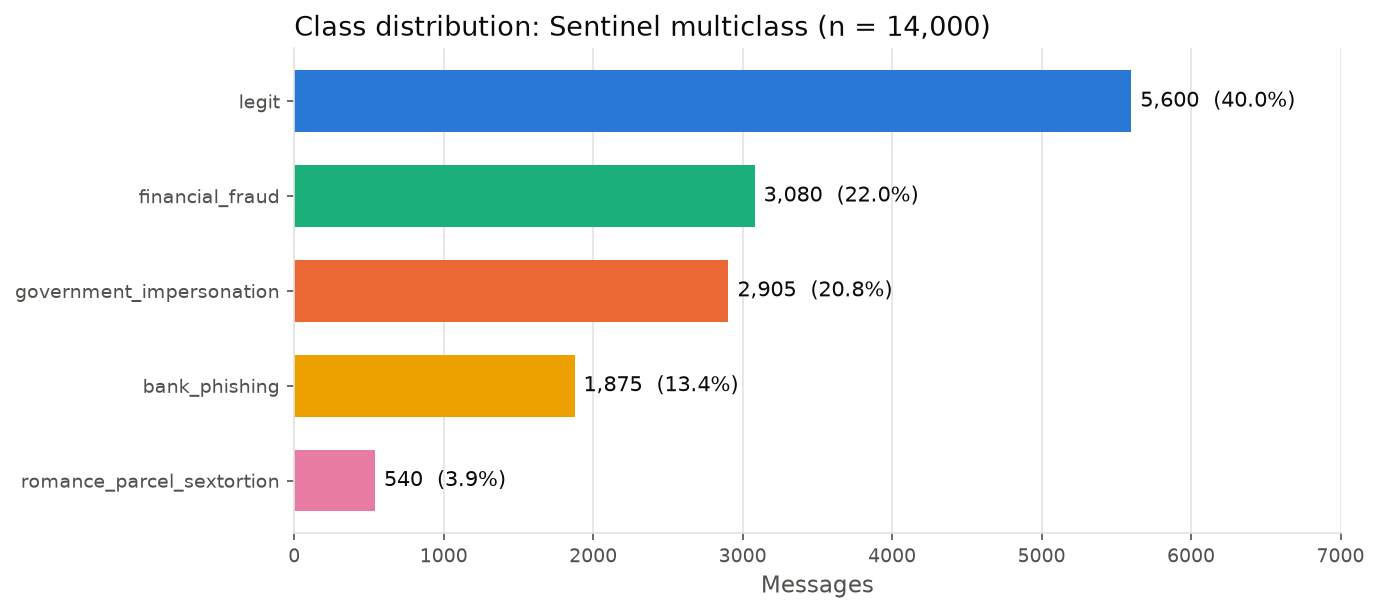

In [5]:
counts = sent["label_name"].value_counts().reindex(CLASSES)
order = counts.sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.2), facecolor="white")
bars = ax.barh(order, counts[order], color=[CLASS_COLORS[c] for c in order], height=0.65)
for b, c in zip(bars, order):
    ax.text(b.get_width() + 60, b.get_y() + b.get_height() / 2,
            f"{counts[c]:,}  ({100 * counts[c] / len(sent):.1f}%)", va="center", color=INK, fontsize=10)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Messages", color=INK_2)
ax.set_title(f"Class distribution: Sentinel multiclass (n = {len(sent):,})", loc="left", color=INK)
_style(ax); ax.yaxis.grid(False); ax.xaxis.grid(True, color=GRID)
_save(fig, "class_distribution.png"); show("class_distribution.png")

`romance_parcel_sextortion` is only 3.9% of rows, so the models use `class_weight="balanced"`
(where supported) and we report **macro-F1**, not just accuracy.

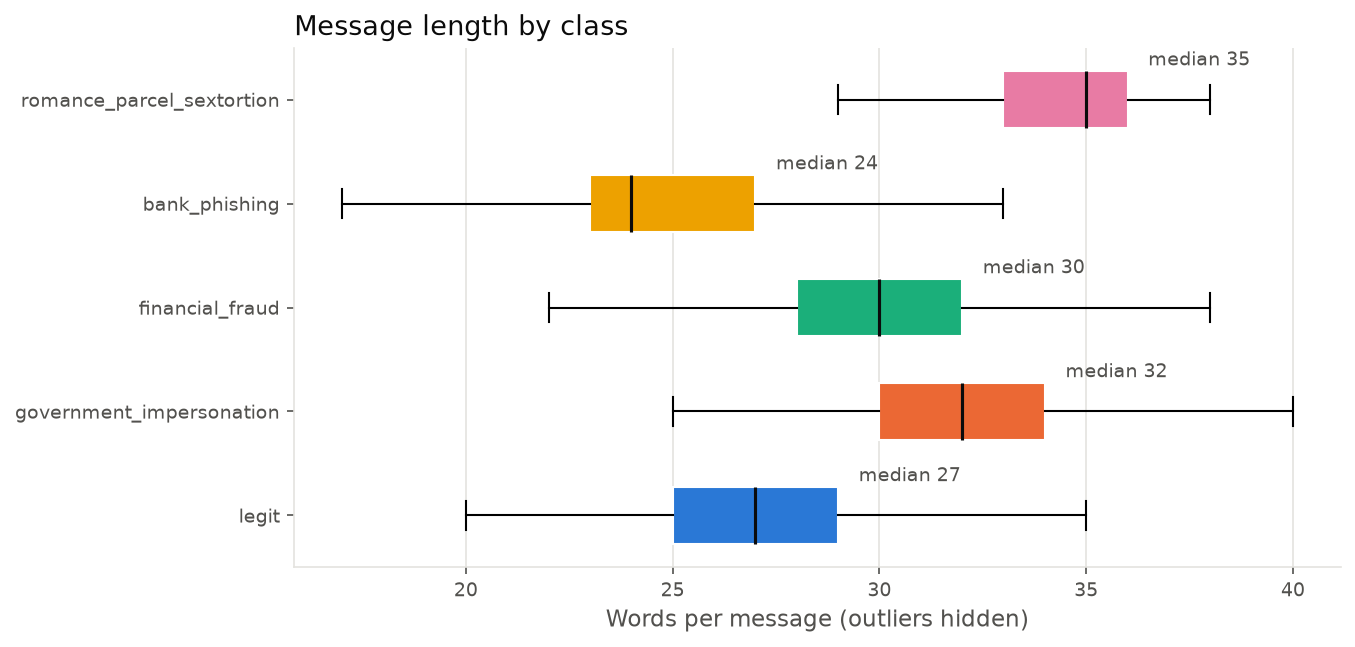

,median words,median characters
label_name,,
legit,27.0,160.0
government_impersonation,32.0,196.0
financial_fraud,30.0,176.0
bank_phishing,24.0,161.0
romance_parcel_sextortion,35.0,179.0


In [6]:
feat = add_features(sent)
feat["is_scam"] = feat["label_name"] != "legit"
fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
data = [feat.loc[feat.label_name == c, "n_words"] for c in CLASSES]
bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.55, showfliers=False,
                medianprops={"color": INK, "linewidth": 1.5})
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_edgecolor("white")
ax.set_yticks(range(1, len(CLASSES) + 1), CLASSES)
for i, d in enumerate(data, start=1):
    ax.text(d.quantile(0.75) + 0.5, i + 0.33, f"median {d.median():.0f}", fontsize=9, color=INK_2)
ax.set_xlabel("Words per message (outliers hidden)", color=INK_2)
ax.set_title("Message length by class", loc="left", color=INK)
_style(ax); ax.yaxis.grid(False); ax.xaxis.grid(True, color=GRID)
_save(fig, "message_length_by_class.png"); show("message_length_by_class.png")
display(feat.groupby("label_name")[["n_words", "length"]].median().reindex(CLASSES)
            .rename(columns={"n_words": "median words", "length": "median characters"}))

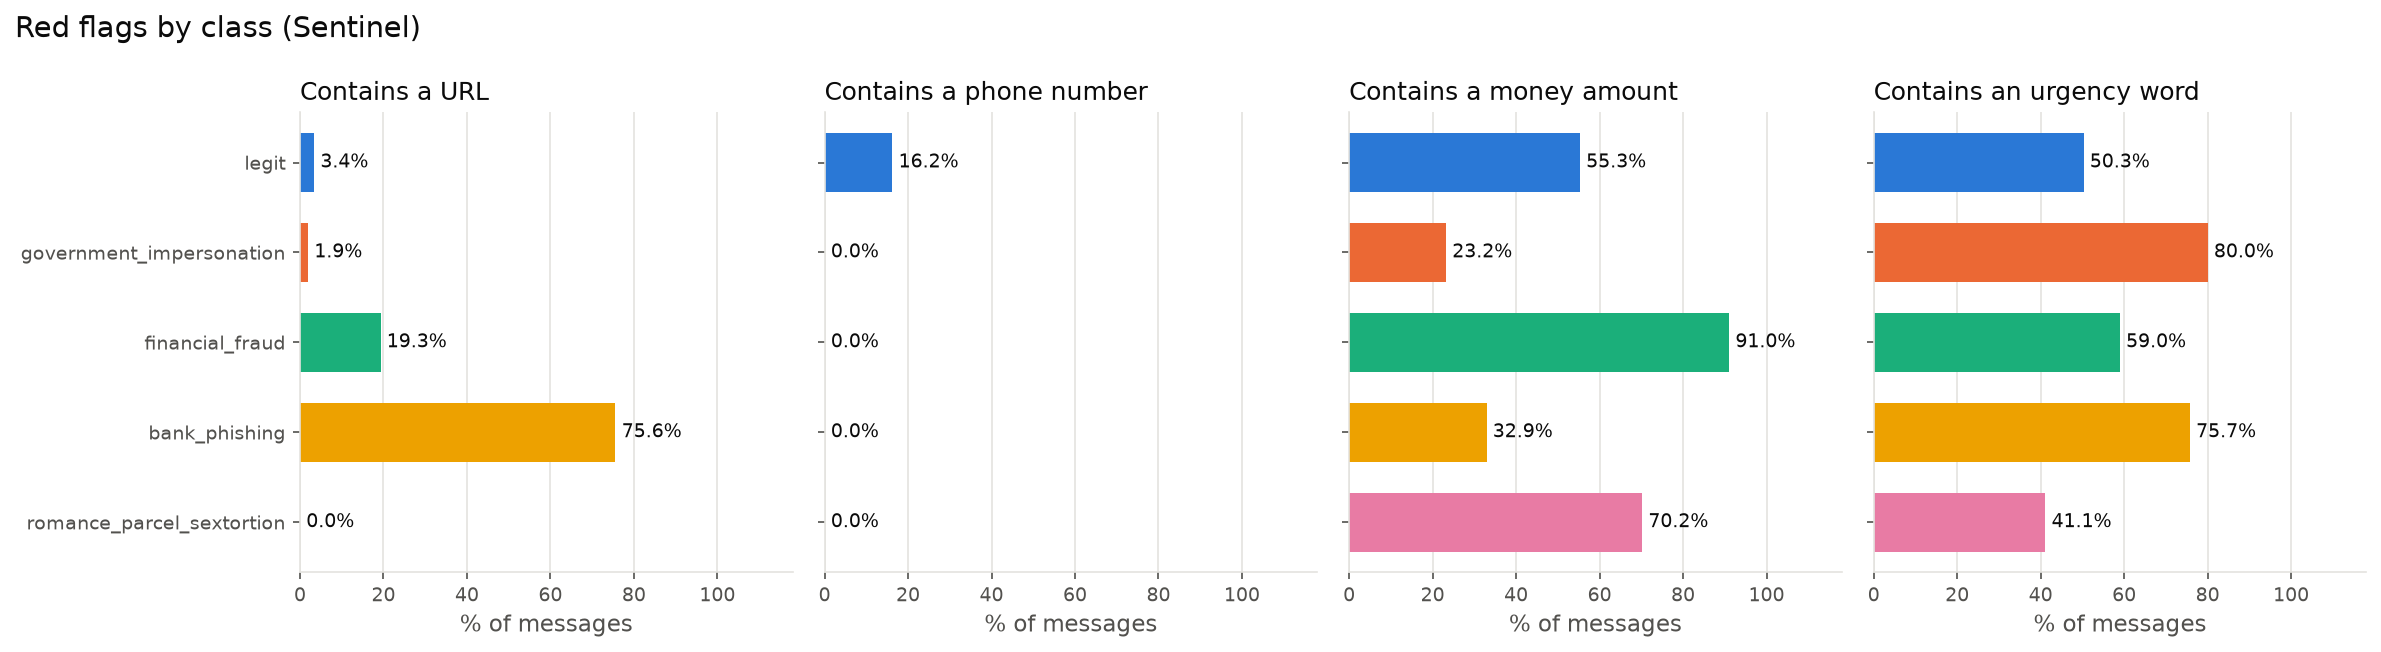

,has_url,has_phone,has_amount,has_urgency
label_name,,,,
legit,3.4,16.2,55.3,50.3
government_impersonation,1.9,0.0,23.2,80.0
financial_fraud,19.3,0.0,91.0,59.0
bank_phishing,75.6,0.0,32.9,75.7
romance_parcel_sextortion,0.0,0.0,70.2,41.1


metrics.json eda block: {'pct_url_scam': 24.6071, 'pct_url_legit': 3.375, 'pct_phone_scam': 0.0, 'pct_phone_legit': 16.2321, 'pct_amount_scam': 53.2619, 'pct_amount_legit': 55.2857, 'avg_words_scam': 29.8455, 'avg_words_legit': 26.9282}


In [7]:
feat["has_urgency"] = feat["urgency_count"] > 0
flags = [("has_url", "Contains a URL"), ("has_phone", "Contains a phone number"),
         ("has_amount", "Contains a money amount"), ("has_urgency", "Contains an urgency word")]
pct = feat.groupby("label_name")[[f for f, _ in flags]].mean().reindex(CLASSES) * 100

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True, facecolor="white")
for ax, (f, title) in zip(axes, flags):
    b = ax.barh(CLASSES[::-1], pct.loc[CLASSES[::-1], f],
                color=[CLASS_COLORS[c] for c in CLASSES[::-1]], height=0.65)
    for bar in b:
        ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2,
                f"{bar.get_width():.1f}%", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, 118); ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel("% of messages", color=INK_2)
    _style(ax); ax.yaxis.grid(False); ax.xaxis.grid(True, color=GRID)
fig.suptitle("Red flags by class (Sentinel)", x=0.01, ha="left", color=INK, fontsize=14)
fig.tight_layout()
_save(fig, "red_flags_by_class.png"); show("red_flags_by_class.png")
display(pct.round(1))
print("metrics.json eda block:", M["eda"])

**Top n-grams per class** (bigrams after cleaning, English stop words removed, by count):

In [8]:
def top_ngrams(texts, n=8, ngram=(2, 2)):
    cv = CountVectorizer(ngram_range=ngram, token_pattern=TOKEN_PATTERN, lowercase=False,
                         stop_words="english")
    X = cv.fit_transform([clean_text(t) for t in texts])
    freq = np.asarray(X.sum(axis=0)).ravel()
    names = cv.get_feature_names_out()
    return [f"{names[i]} ({freq[i]})" for i in np.argsort(-freq)[:n]]

display(pd.DataFrame({c: top_ngrams(sent.loc[sent.label_name == c, "text"]) for c in CLASSES}))

,legit,government_impersonation,financial_fraud,bank_phishing,romance_parcel_sextortion
0,balance <AMOUNT> (732),mobile number (365),pay <AMOUNT> (1061),account ending (664),need <AMOUNT> (119)
1,account ending (711),pan card (314),fee <AMOUNT> (354),card ending (278),transfer india (92)
2,minutes share (630),cybercrime division (311),<AMOUNT> receive (293),restore access (266),pay <AMOUNT> (82)
3,bank india (605),investigation cooperate (309),processing fee (265),bank india (241),<AMOUNT> customs (82)
4,ref txn (550),transfer <AMOUNT> (305),<AMOUNT> pay (217),credit card (233),send <AMOUNT> (75)
5,<AMOUNT> credited (516),report online (280),earn <AMOUNT> (189),incomplete kyc (214),assets worth (70)
6,valid 10 (479),voter id (271),link <URL> (175),bank account (205),worth crores (70)
7,10 minutes (479),pay <AMOUNT> (257),registration fee (150),transaction <AMOUNT> (182),officer deployed (54)


## 3. Dataset biases

These are properties of the training data that a model can exploit as shortcuts, or that limit
how far its results generalise.

### 3.1 Phone numbers only in legit messages

In [9]:
e = M["eda"]
print(f"Messages with a phone number: scam {e['pct_phone_scam']:.1f}%  vs  legit {e['pct_phone_legit']:.1f}%")
print("Real scams very often contain a phone number, so a <PHONE> token would teach the model "
      "'phone number -> legit'.\nFix A: phone numbers are removed from the text the model sees "
      "(has_phone is still used for EDA and the red-flag checklist). Effect:")
ab = M["phone_token_ablation"]
display(pd.DataFrame({
    "random: with <PHONE>": {m: v["with_phone"] for m, v in ab["macro_f1_random"].items()},
    "random: phones removed": {m: v["without_phone"] for m, v in ab["macro_f1_random"].items()},
    "grouped: with <PHONE>": {m: v["with_phone"] for m, v in ab["macro_f1_grouped"].items()},
    "grouped: phones removed": {m: v["without_phone"] for m, v in ab["macro_f1_grouped"].items()},
}).rename_axis("macro-F1"))
display(pd.DataFrame([{"set": k, "version": tag, **v[key]} for k, v in ab["ood"].items()
                      for tag, key in [("with <PHONE>", "with_phone"), ("phones removed", "without_phone")]])
        .set_index(["set", "version"]))

Messages with a phone number: scam 0.0%  vs  legit 16.2%
Real scams very often contain a phone number, so a <PHONE> token would teach the model 'phone number -> legit'.
Fix A: phone numbers are removed from the text the model sees (has_phone is still used for EDA and the red-flag checklist). Effect:


,random: with <PHONE>,random: phones removed,grouped: with <PHONE>,grouped: phones removed
macro-F1,,,,
Naive Bayes,0.9756,0.9756,0.9388,0.9388
Logistic Regression,0.9964,0.9968,0.9573,0.9573
Linear SVM,0.9976,0.9976,0.9851,0.9854
Random Forest,0.9825,0.9824,0.9552,0.9538


n  accuracy  precision  recall      f1
set           version                                                  
hinglish      with <PHONE>    3558    0.6757     0.2534  0.3957  0.3090
              phones removed  3558    0.6928     0.2918  0.4739  0.3612
uci_sms       with <PHONE>    5171    0.7010     0.1781  0.3783  0.2422
              phones removed  5171    0.7142     0.2101  0.4579  0.2881
hinglish_only with <PHONE>      87    0.7701     0.8857  0.6596  0.7561
              phones removed    87    0.7701     0.8857  0.6596  0.7561

### 3.2 "Rs Rs" appears only in legit messages

In [10]:
rsrs = sent[sent.text.str.contains("Rs Rs", regex=False)]
print(f"{len(rsrs)} rows contain the duplicated currency 'Rs Rs':", rsrs.label_name.value_counts().to_dict())
print("Example:", rsrs.text.iloc[0])
print("Cleaning collapses 'Rs Rs 8,900' into a single <AMOUNT> token, so the model cannot use it:")
print("  ->", clean_text(rsrs.text.iloc[0]))

567 rows contain the duplicated currency 'Rs Rs': {'legit': 567}
Example: Axis Bank Alert: Rs 999 debited from account ending 4821 at Reliance Fresh on 05-May. Available balance: Rs Rs 8,900. If not done by you, call Axis Bank helpline immediately.
Cleaning collapses 'Rs Rs 8,900' into a single <AMOUNT> token, so the model cannot use it:
  -> axis bank alert: <AMOUNT> debited from account ending 4821 at reliance fresh on 05-may. available balance: <AMOUNT> . if not done by you, call axis bank helpline immediately.


### 3.3 Inconsistent class boundaries

The 5-class labels were derived from an originally binary dataset. Some message types are spread
across classes, and the `romance_parcel_sextortion` class contains no "parcel" messages:

In [11]:
low = sent.text.str.lower()
kw = ["pnb fraud alert", "ncb", "sim card", "customs", "parcel", "courier", "kyc"]
display(pd.DataFrame({k: sent[low.str.contains(k, regex=False)].label_name.value_counts()
                      for k in kw}).reindex(CLASSES).fillna(0).astype(int).T
        .rename_axis("rows containing ..."))
print("Consequence: class-level predictions for overlapping scam types (e.g. parcel/customs) are "
      "less reliable than the scam-vs-legit decision. Demo sample parcel_01 is predicted "
      f"'{predict(DEMO['parcel_01']['text'])['label']}' although written as romance_parcel_sextortion.")

label_name,legit,government_impersonation,financial_fraud,bank_phishing,romance_parcel_sextortion
rows containing ...,,,,,
pnb fraud alert,0,0,11,0,0
ncb,0,333,40,0,0
sim card,0,213,42,0,0
customs,0,1,255,0,82
parcel,0,1,133,0,0
courier,0,0,7,0,49
kyc,108,0,25,628,0


Consequence: class-level predictions for overlapping scam types (e.g. parcel/customs) are less reliable than the scam-vs-legit decision. Demo sample parcel_01 is predicted 'financial_fraud' although written as romance_parcel_sextortion.


### 3.4 No casual chat in the legit class

Sentinel's legit messages are bank, recharge, delivery and service notifications. There are no
personal or casual messages, so the model has never seen an ordinary chat message as legit:

In [12]:
casual = ["Hi, can you call me when you are free? Need to discuss the project today.",
          "Reached home safely. Will call you tomorrow morning.",
          "Happy birthday! Party at my place tonight, come by 8."]
display(pd.DataFrame([{"message": t, **{k: predict(t)[k] for k in ("label", "scam_prob", "risk")}}
                      for t in casual]))

model = load_model()
ham = uci[uci.label == 0]
ham_pred = pd.Series(model.predict(list(ham.text))).map(dict(enumerate(CLASSES)))
print(f"UCI ham (normal personal SMS) predicted as a scam class: {(ham_pred != 'legit').mean():.1%} "
      f"of {len(ham)}")
display(ham_pred.value_counts().rename("UCI ham predicted as").to_frame())

,message,label,scam_prob,risk
0,"Hi, can you call me when you are free? Need to discuss the project today.",romance_parcel_sextortion,0.8314,High
1,Reached home safely. Will call you tomorrow morning.,legit,0.1228,Low
2,"Happy birthday! Party at my place tonight, come by 8.",legit,0.0102,Low


UCI ham (normal personal SMS) predicted as a scam class: 24.9% of 4518


,UCI ham predicted as
legit,3394
financial_fraud,532
government_impersonation,287
romance_parcel_sextortion,248
bank_phishing,57


## 4. Model comparison

TF-IDF (word 1-2 grams + char 3-5 grams) with four classifiers, trained on two splits.
All numbers are read from `artifacts/metrics.json`.

In [13]:
cols = ["accuracy", "macro_f1", "weighted_f1", "roc_auc_ovr", "train_time_s"]
rand = pd.DataFrame(M["models"]).T[cols]
grp = pd.DataFrame(M["models_grouped"]).T[cols]
display(Markdown(f"**Random stratified 80/20 split** (train {M['dataset']['train_rows']}, "
                 f"test {M['dataset']['test_rows']})"))
display(rand.sort_values("macro_f1", ascending=False))
display(Markdown(f"**Template-grouped split** (train {M['dataset_grouped']['train_rows']}, "
                 f"test {M['dataset_grouped']['test_rows']}, {M['dataset_grouped']['n_templates']} templates, "
                 "none shared)"))
display(grp.sort_values("macro_f1", ascending=False))
display(Markdown(f"**Best model: {M['best_model']}.** {M['best_model_reason']}"))
display(pd.DataFrame({"random split": pd.DataFrame(M["per_class"]).T["f1"],
                      "grouped split": pd.DataFrame(M["per_class_grouped"]).T["f1"]})
        .rename_axis(f"{M['best_model']} per-class F1"))

**Random stratified 80/20 split** (train 11200, test 2800)

,accuracy,macro_f1,weighted_f1,roc_auc_ovr,train_time_s
Linear SVM,0.9979,0.9976,0.9979,1.0000,2.7774
Logistic Regression,0.9971,0.9968,0.9971,1.0000,1.8311
Random Forest,0.9821,0.9824,0.9821,0.9992,1.5151
Naive Bayes,0.9768,0.9756,0.9768,0.9971,1.0105


**Template-grouped split** (train 11200, test 2800, 6693 templates, none shared)

,accuracy,macro_f1,weighted_f1,roc_auc_ovr,train_time_s
Linear SVM,0.9854,0.9854,0.9853,0.9995,2.7755
Logistic Regression,0.9679,0.9573,0.9679,0.9993,1.7582
Random Forest,0.9611,0.9538,0.9608,0.9958,1.5074
Naive Bayes,0.9486,0.9388,0.9482,0.9947,1.0061


**Best model: Linear SVM.** Linear SVM has the highest macro-F1 on the template-grouped split (0.9854 vs Logistic Regression 0.9573). The grouped split is used because the random split lets near-identical templated messages appear in both train and test, which inflates scores (random-split macro-F1 for Linear SVM: 0.9976).

,random split,grouped split
Linear SVM per-class F1,,
legit,0.9996,0.9996
government_impersonation,0.9983,0.9692
financial_fraud,0.9968,0.9713
bank_phishing,0.9933,0.9867
romance_parcel_sextortion,1.0000,1.0000


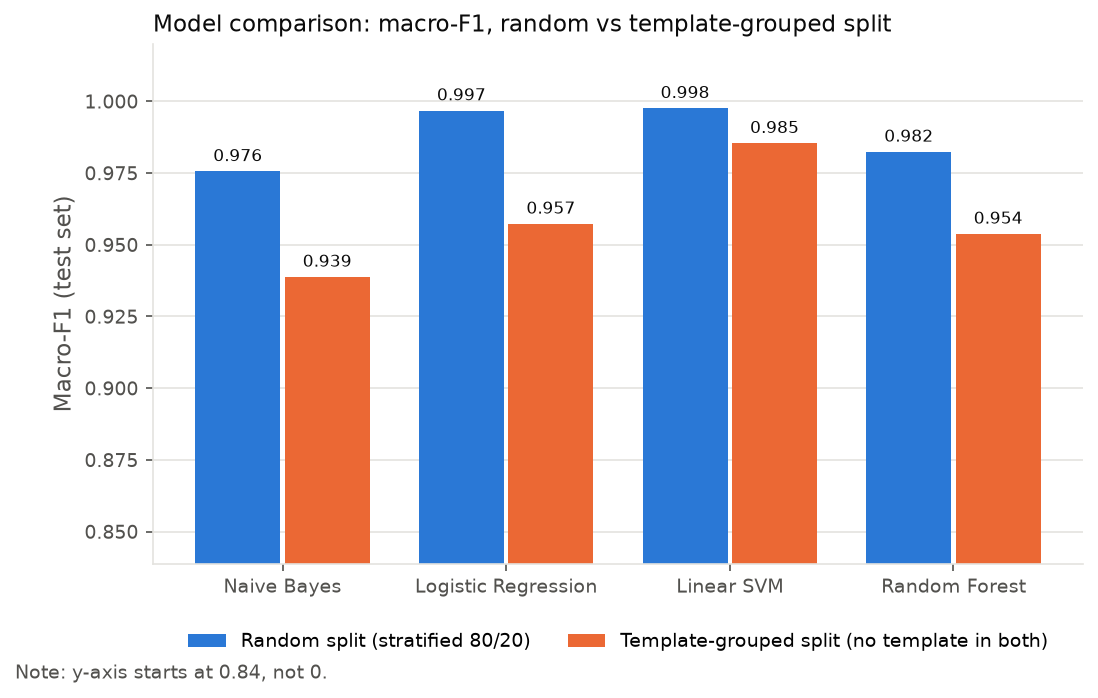

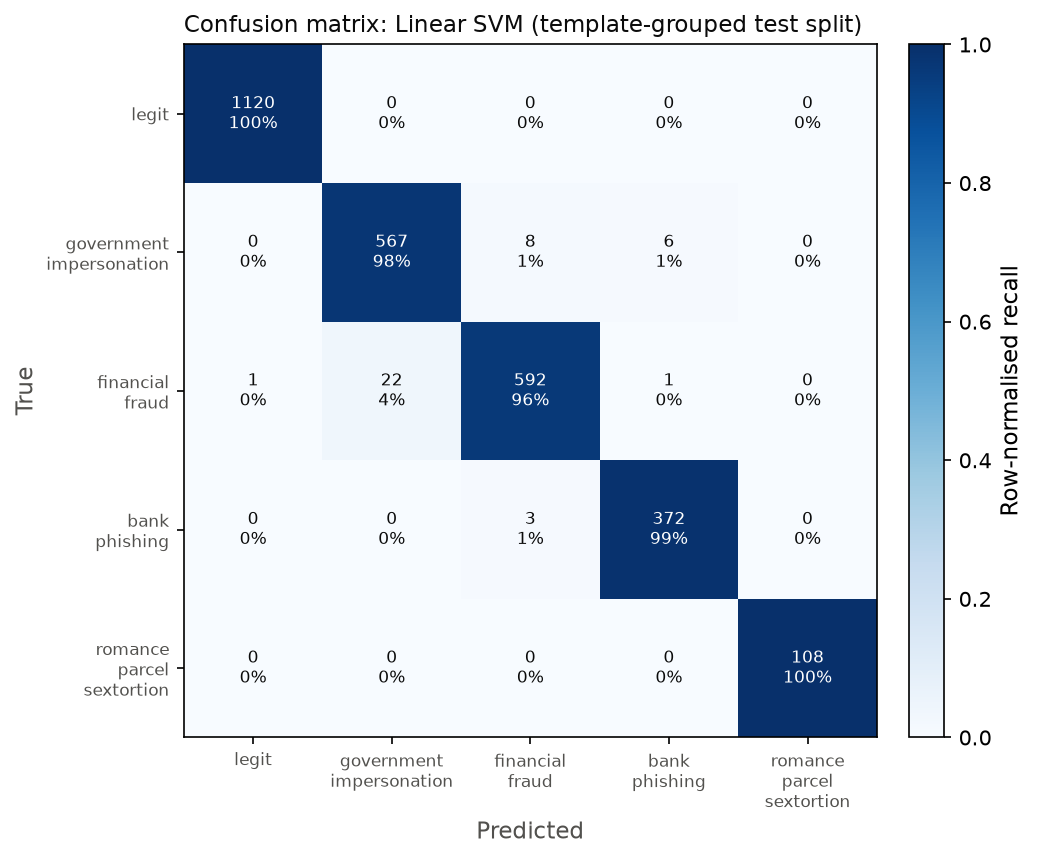

In [14]:
plot_model_comparison(M["models"], M["models_grouped"])
show("model_comparison.png")
plot_confusion(CM["grouped"][M["best_model"]], M["best_model"])
show("confusion_matrix.png")

**Out-of-domain test.** Binary scam vs legit: a message counts as scam if the predicted class is
any non-legit class. Positive class = scam. These use the deployed model (`artifacts/model.joblib`).

,n,accuracy,precision,recall,f1
hinglish,3558.0,0.6928,0.2918,0.4739,0.3612
uci_sms,5171.0,0.7142,0.2101,0.4579,0.2881
hinglish_only,87.0,0.7701,0.8857,0.6596,0.7561


Exact duplicates dropped before evaluation: {'uci_sms': 403, 'hinglish': 229}


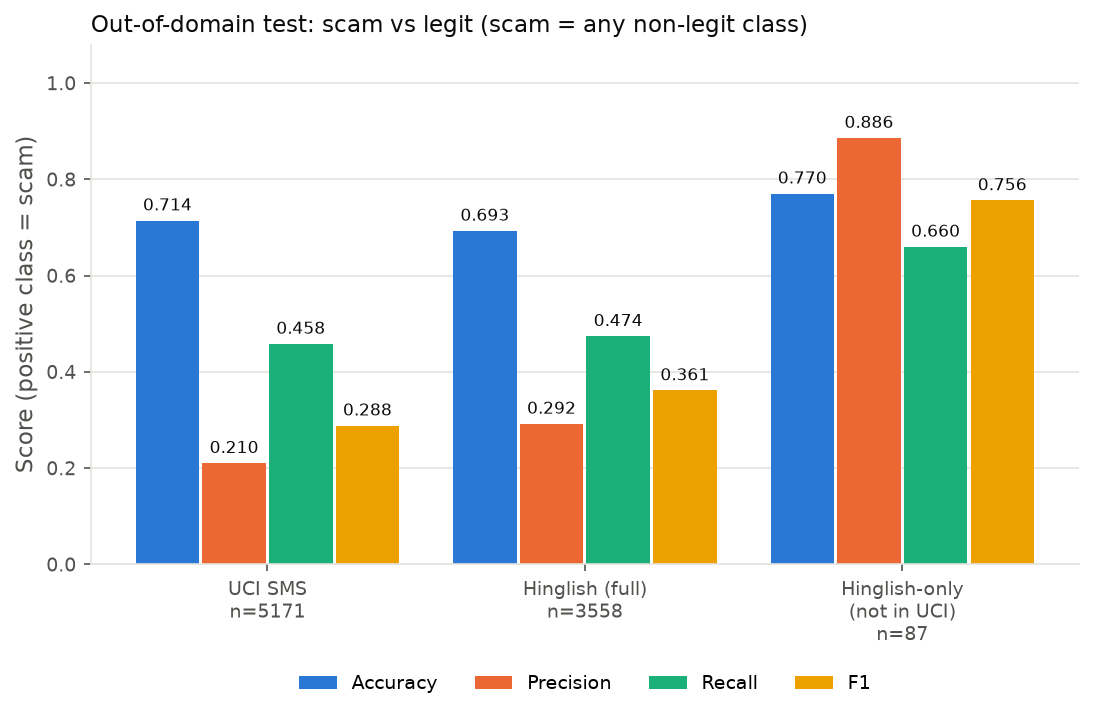

In [15]:
display(pd.DataFrame(M["ood"]).T)
print("Exact duplicates dropped before evaluation:", M["ood_duplicates_removed"])
plot_ood(M["ood"])
show("ood_results.png")

In-domain scores are near-perfect even on the grouped split, because Sentinel is synthetic and
templated. The out-of-domain scores are the realistic picture: low precision on UCI is caused
by casual messages being called scams (section 3.4), and low recall by UK prize spam not looking
like Indian fraud.

## 5. Explainability

**Global:** the top word n-grams per class from the Linear SVM coefficients (averaged over the
calibration folds; word part of the TF-IDF union only; numbers and single characters dropped).

In [16]:
gw_raw = explain_global(15, drop_stopwords=False)
display(Markdown("**Unfiltered** (numbers and single characters dropped only):"))
display(pd.DataFrame({c: [f"{w} ({v:.2f})" for w, v in gw_raw[c][:10]] for c in CLASSES}))

**Unfiltered** (numbers and single characters dropped only):

,legit,government_impersonation,financial_fraud,bank_phishing,romance_parcel_sextortion
0,app (0.72),si (2.07),pnb visa (1.80),india security (1.60),am (0.70)
1,for (0.58),cybercrime (1.61),pnb fraud (1.62),bank visa (1.17),my (0.48)
2,otp (0.46),trai (1.55),ncb (1.09),bank transaction (1.13),an (0.46)
3,order (0.46),pan card (1.50),your sim (1.05),bank (1.09),me (0.45)
4,may (0.43),your pan (1.46),sim card (1.03),bank fraud (1.07),and will (0.39)
5,successfully (0.41),pan (1.45),sim (1.00),of india (1.03),with you (0.36)
6,txn (0.38),cbi (1.37),crime (0.99),<URL> (1.01),video (0.33)
7,credited to (0.36),dcp (1.27),crime cell (0.97),india fraud (0.90),adult (0.32)
8,valid (0.34),your voter (1.13),cyber crime (0.97),hdfc bank (0.88),help me (0.30)
9,balance (0.34),your passport (1.12),acp (0.85),axis bank (0.85),your screen (0.28)


Unfiltered, `romance_parcel_sextortion` is led by first-person words (*am, my, me*) because
romance and sextortion messages are written as one person talking to you ("I am a doctor...",
"help me"), unlike the impersonal notices in the other classes. For display (the figure, the
app and `metrics.json` top_words) we drop n-grams made **only** of English stop words, so
phrases like *help me* and *with you* survive. The model itself is unchanged.

**Stop-word n-grams removed** (used for the figure, the app and metrics.json):

,legit,government_impersonation,financial_fraud,bank_phishing,romance_parcel_sextortion
0,app (0.72),si (2.07),pnb visa (1.80),india security (1.60),video (0.33)
1,otp (0.46),cybercrime (1.61),pnb fraud (1.62),bank visa (1.17),adult (0.32)
2,order (0.46),trai (1.55),ncb (1.09),bank transaction (1.13),help me (0.30)
3,successfully (0.41),pan card (1.50),your sim (1.05),bank (1.09),your screen (0.28)
4,txn (0.38),your pan (1.46),sim card (1.03),bank fraud (1.07),hi (0.28)
5,credited to (0.36),pan (1.45),sim (1.00),of india (1.03),screen (0.25)
6,valid (0.34),cbi (1.37),crime (0.99),<URL> (1.01),video call (0.23)
7,balance (0.34),dcp (1.27),crime cell (0.97),india fraud (0.90),need <AMOUNT> (0.21)
8,thank (0.33),your voter (1.13),cyber crime (0.97),hdfc bank (0.88),to india (0.21)
9,thank you (0.33),your passport (1.12),acp (0.85),axis bank (0.85),working in (0.21)


metrics.json top_words: {'legit': ['app', 'otp', 'order', 'successfully', 'txn'], 'government_impersonation': ['si', 'cybercrime', 'trai', 'pan card', 'your pan'], 'financial_fraud': ['pnb visa', 'pnb fraud', 'ncb', 'your sim', 'sim card'], 'bank_phishing': ['india security', 'bank visa', 'bank transaction', 'bank', 'bank fraud'], 'romance_parcel_sextortion': ['video', 'adult', 'help me', 'your screen', 'hi']}


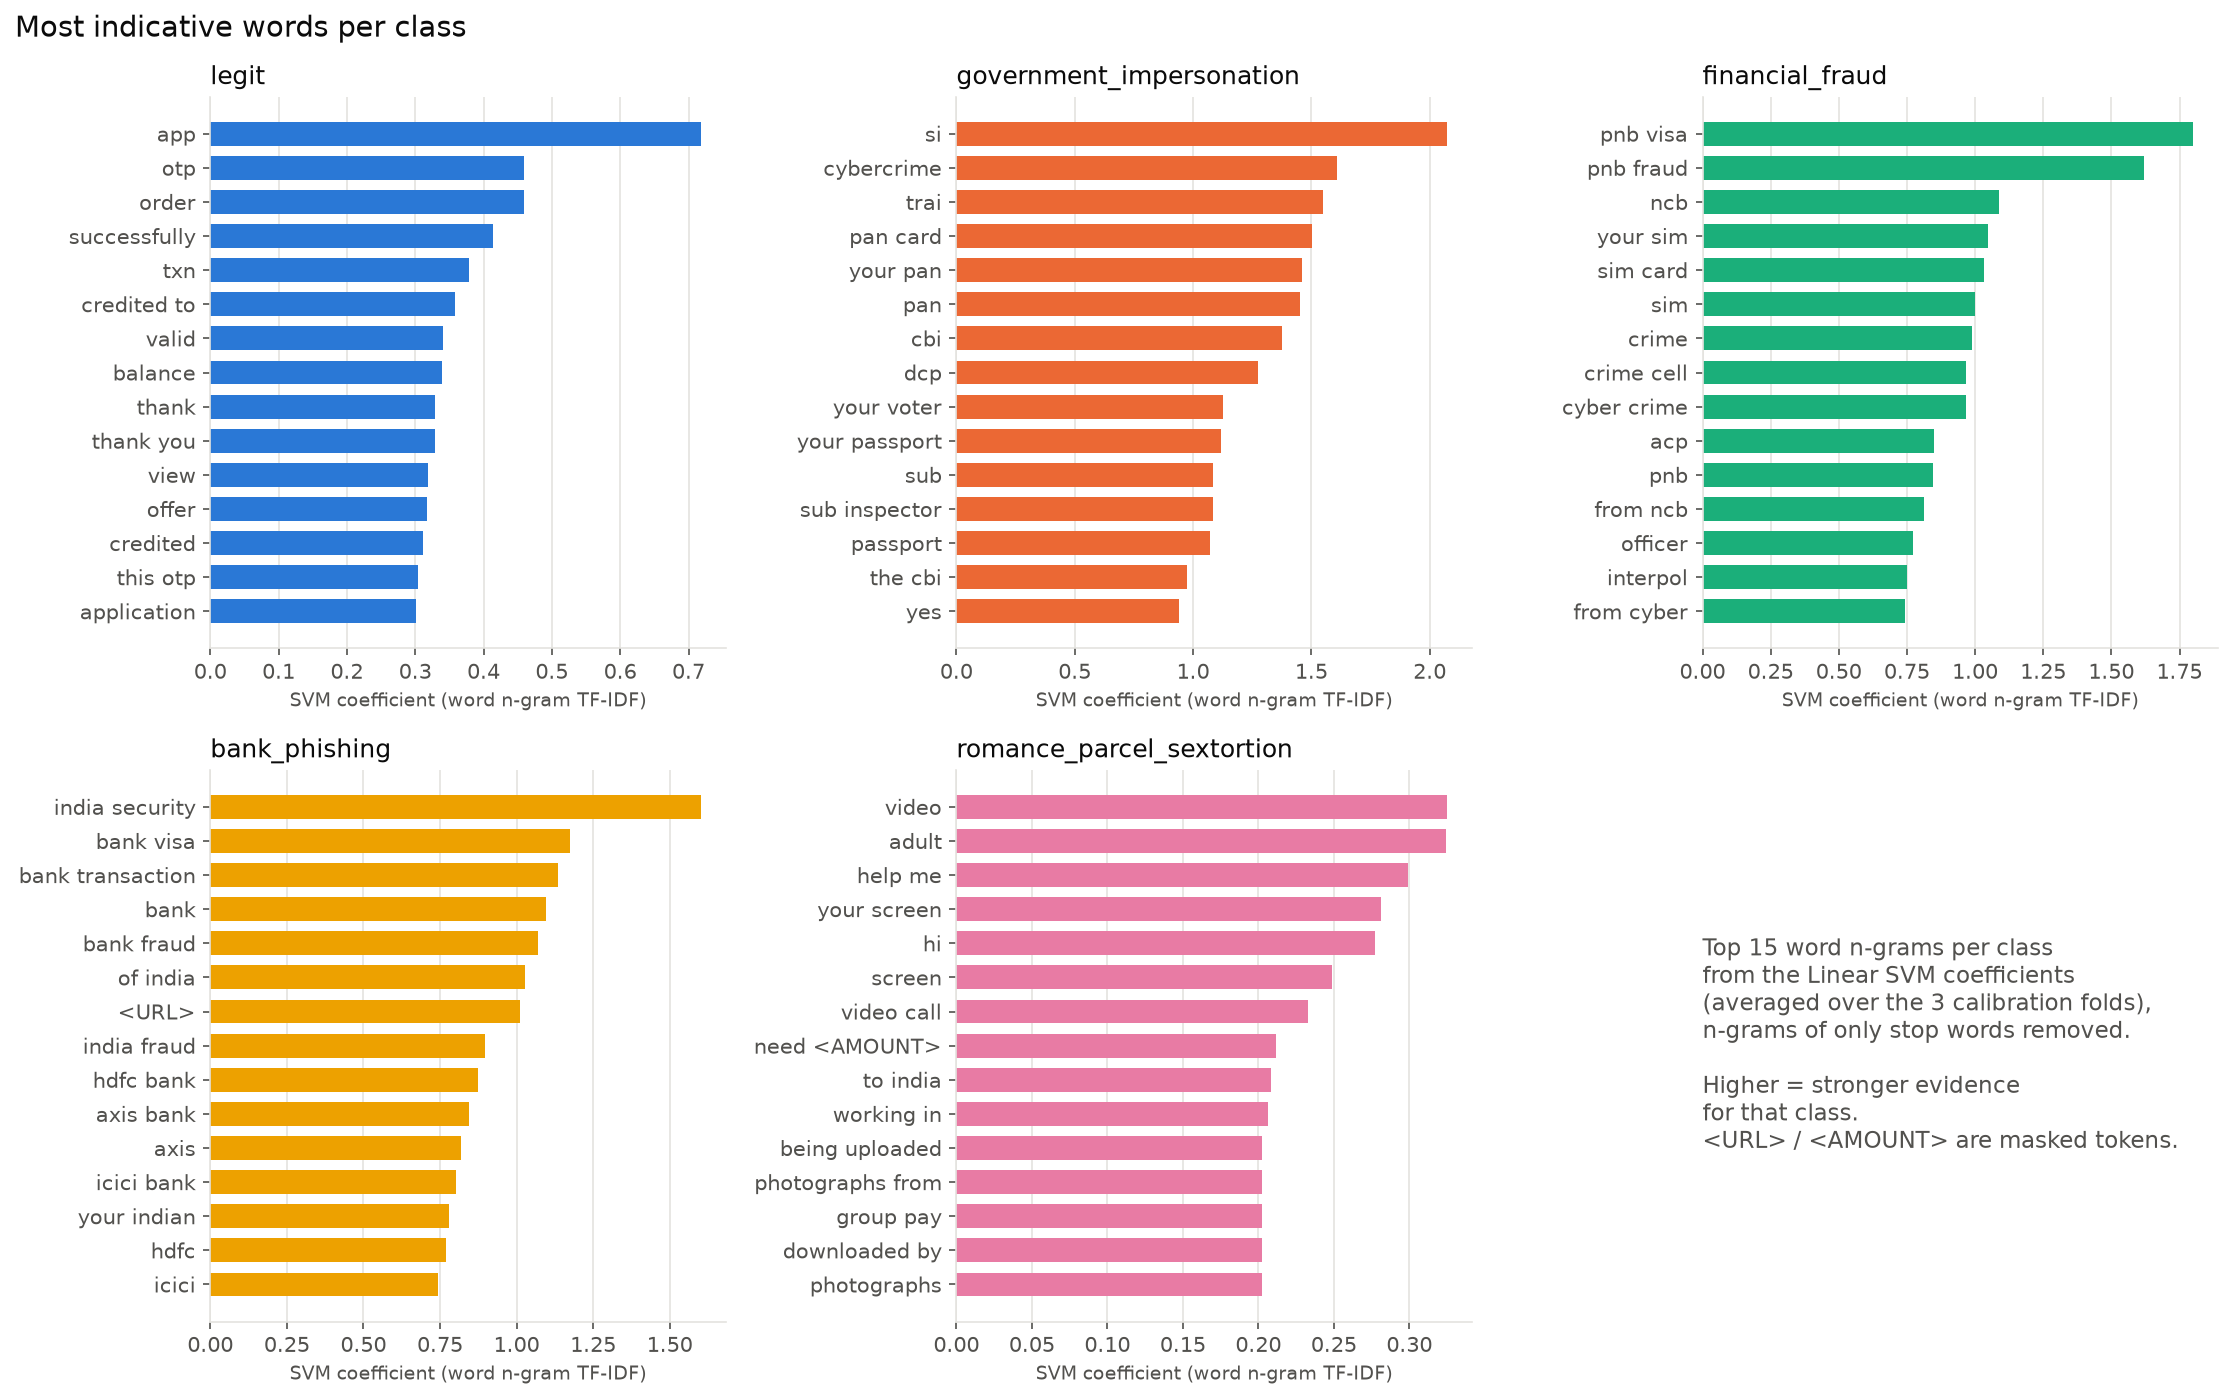

In [17]:
gw = explain_global(15)
display(Markdown("**Stop-word n-grams removed** (used for the figure, the app and metrics.json):"))
display(pd.DataFrame({c: [f"{w} ({v:.2f})" for w, v in gw[c][:10]] for c in CLASSES}))
print("metrics.json top_words:", M["top_words"])
plot_top_words(gw)
show("top_words_per_class.png")

**Local (LIME):** for one message, which of the words the user typed pushed the prediction.
Positive weight = pushes toward the class shown. When the prediction is legit, we also show the
words pushing toward the most likely scam class.

In [18]:
for sid in ["bank_01", "hing_01", "legit_01"]:
    text = DEMO[sid]["text"]
    p, ex = predict(text), explain_local(text)
    display(Markdown(f"**{sid}** (expected: {DEMO[sid]['expected']}) -> predicted **{p['label']}**, "
                     f"scam_prob {p['scam_prob']:.3f}, risk {p['risk']}\n\n> {text}"))
    tbl = pd.DataFrame(ex["words"], columns=["word", f"weight -> {ex['label']}"])
    if ex["scam_class"]:
        tbl = pd.concat([tbl, pd.DataFrame(ex["scam_words"],
                         columns=["word ", f"weight -> {ex['scam_class']}"])], axis=1)
    display(tbl)

**bank_01** (expected: bank_phishing) -> predicted **bank_phishing**, scam_prob 0.996, risk High

> Dear Customer, your XYZ Bank KYC has expired and your account will be BLOCKED today. Update your PAN details now to avoid suspension: http://kyc-verify-update.example/login

,word,weight -> bank_phishing
0,suspension,0.1268
1,PAN,-0.0774
2,KYC,0.0724
3,Bank,0.0673
4,http,0.0636
5,account,0.0627
6,and,0.0611
7,BLOCKED,0.0491


**hing_01** (expected: scam (government_impersonation / financial_fraud)) -> predicted **legit**, scam_prob 0.100, risk Low

> Priya grahak, aapka bijli connection aaj raat 9:30 baje kaat diya jayega kyunki pichle mahine ka bill update nahi hua hai. Turant electricity officer ko is number par call kare: 90000 33445

,word,weight -> legit,word,weight -> financial_fraud
0,officer,-0.2714,officer,0.2900
1,bill,0.1972,bill,-0.1595
2,electricity,0.1369,electricity,-0.1095
3,update,0.1003,update,-0.1088
4,number,-0.0948,number,0.1076
5,baje,0.0736,call,-0.0731
6,mahine,0.0527,connection,-0.0610
7,Priya,-0.0333,mahine,-0.0440


**legit_01** (expected: legit) -> predicted **legit**, scam_prob 0.000, risk Low

> 482913 is your OTP for login. It is valid for 10 minutes. Do not share it with anyone, including bank staff.

,word,weight -> legit,word,weight -> romance_parcel_sextortion
0,valid,0.0039,with,0.0002
1,not,0.0036,share,-0.0001
2,OTP,0.0035,OTP,-0.0001
3,is,0.0032,is,-0.0001
4,your,0.0031,for,-0.0001
5,staff,0.0030,bank,-0.0001
6,10,0.0028,your,-0.0001
7,It,-0.0019,not,-0.0001


For `hing_01` the model predicts legit: the words *bill*, *electricity* and *update* look like
the utility/bill notifications in the legit class. *officer* and *number* push toward a scam
class, but not enough. Utility-disconnection scams are absent from Sentinel, which is why the
rule layer (section 6) exists. For `legit_01` the weights are tiny because the model is almost
100% sure; LIME explanations are least informative when the probability is saturated.

## 6. Rule layer (red flags)

`src/red_flags.py` checks 9 hand-written scam tactics in English and Hindi/Hinglish (threats,
urgency, payment request, OTP/PIN, call this number, link, secrecy, new-number impersonation,
authority impersonation). It is **separate from the model** and never changes the label,
probabilities, scam_prob or risk. Advisory = *high* for 3+ flags, *caution* for 2.

In [19]:
rl = M["rule_layer"]
display(pd.DataFrame(rl["false_alarms"]).T.rename_axis("false alarms on legit messages (%)"))
display(pd.DataFrame(rl["scam_recall"]).T.rename_axis("scam recall: ML only vs ML OR advisory=high"))

,n,pct_advisory_any,pct_advisory_high
false alarms on legit messages (%),,,
sentinel_legit_test,1120.0,6.1607,0.0
uci_ham,4518.0,0.0443,0.0


,n_scam,recall_ml_only,recall_ml_or_high,precision_ml_only,precision_ml_or_high
scam recall: ML only vs ML OR advisory=high,,,,,
uci_sms,653.0,0.4579,0.4579,0.2101,0.2101
hinglish_only,47.0,0.6596,0.6809,0.8857,0.8889


In [20]:
rows = []
for sid, m in DEMO.items():
    a = analyse(m["text"])
    rows.append({"id": sid, "expected": m["expected"], "ML label": a["label"], "risk": a["risk"],
                 "advisory": a["advisory"], "flags": ", ".join(f["flag"] for f in a["red_flags"])})
display(pd.DataFrame(rows).set_index("id"))

,expected,ML label,risk,advisory,flags
id,,,,,
gov_01,government_impersonation,government_impersonation,High,high,"threat_disconnect_block, urgency, secrecy, authority_impersonation"
gov_02,government_impersonation,government_impersonation,High,high,"threat_disconnect_block, urgency, call_this_number, authority_impersonation"
bank_01,bank_phishing,bank_phishing,High,high,"threat_disconnect_block, urgency, link_present"
bank_02,bank_phishing,bank_phishing,High,caution,"threat_disconnect_block, share_otp_pin"
fin_01,financial_fraud,financial_fraud,High,none,payment_request
fin_02,financial_fraud,financial_fraud,High,caution,"urgency, payment_request"
parcel_01,romance_parcel_sextortion,financial_fraud,High,high,"urgency, payment_request, link_present, authority_impersonation"
romance_01,romance_parcel_sextortion,romance_parcel_sextortion,High,caution,"payment_request, authority_impersonation"
hing_01,scam (government_impersonation / financial_fraud),legit,Low,high,"threat_disconnect_block, urgency, call_this_number, authority_impersonation"


**Caveat.** The rules were written from general scam-awareness guidance without looking at the
UCI or hinglish_only rows, so those two sets are fair tests of the rule layer. The demo samples
are **not** an independent test: their texts were seen while the rules were being written, so
the demo results above (e.g. hing_01 and hing_02 getting advisory = high) should not be read as
evidence that the rules generalise.

## 7. Limitations

- **Synthetic, templated training data.** Even with no template shared between train and test,
  templates that differ only in bank names or amounts remain, so the ~98.5% grouped macro-F1 is
  an upper bound, not a real-world estimate.
- **Inconsistent class labels.** Similar messages (PNB fraud alerts, NCB impersonation,
  parcel/customs scams) appear under different classes, so the exact scam *type* is less
  reliable than the scam-vs-legit decision.
- **Narrow legit class.** Legit messages are only service notifications, so ordinary personal
  messages are often flagged as scams (low out-of-domain precision).
- **Missing scam types.** Utility-disconnection and "new number, send money" scams are absent
  from the training data, so the model misses them; the rule layer only partly compensates.
- **Small Hinglish test.** hinglish_only has 87 rows (47 scams), so its scores have a wide
  margin of error; the rest of the "Hinglish" set is UCI SMS.
- **Old, foreign spam in UCI.** UCI spam is mostly 2000s UK marketing spam, not Indian fraud.
- **Explanations are approximate.** LIME samples perturbations; weights vary slightly between
  runs and are near zero when the model is very confident.
- **Hand-written rules** are not validated on an independent Indian scam set.